In [1]:
import seaborn as sns
df = sns.load_dataset("taxis")
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [3]:
df.isnull().sum()
df.isnull().sum().sum()
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

,0
payment,44
pickup_zone,26
dropoff_zone,45
pickup_borough,26
dropoff_borough,45


In [5]:
df.info()
df['passengers'] = df['passengers'].fillna(df['passengers'].median())
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

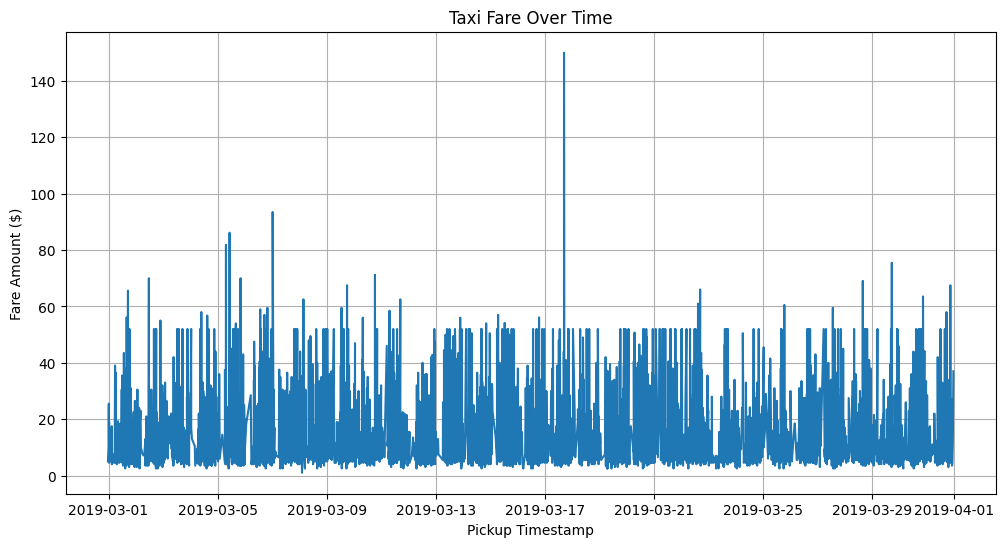

In [16]:
# Line Chart
import pandas as pd
import matplotlib.pyplot as plt

df['pickup'] = pd.to_datetime(df['pickup'])

df = df.sort_values(by='pickup')

plt.figure(figsize=(12, 6))
plt.plot(df['pickup'], df['fare'])

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare Amount ($)')

plt.grid(True)
plt.show()

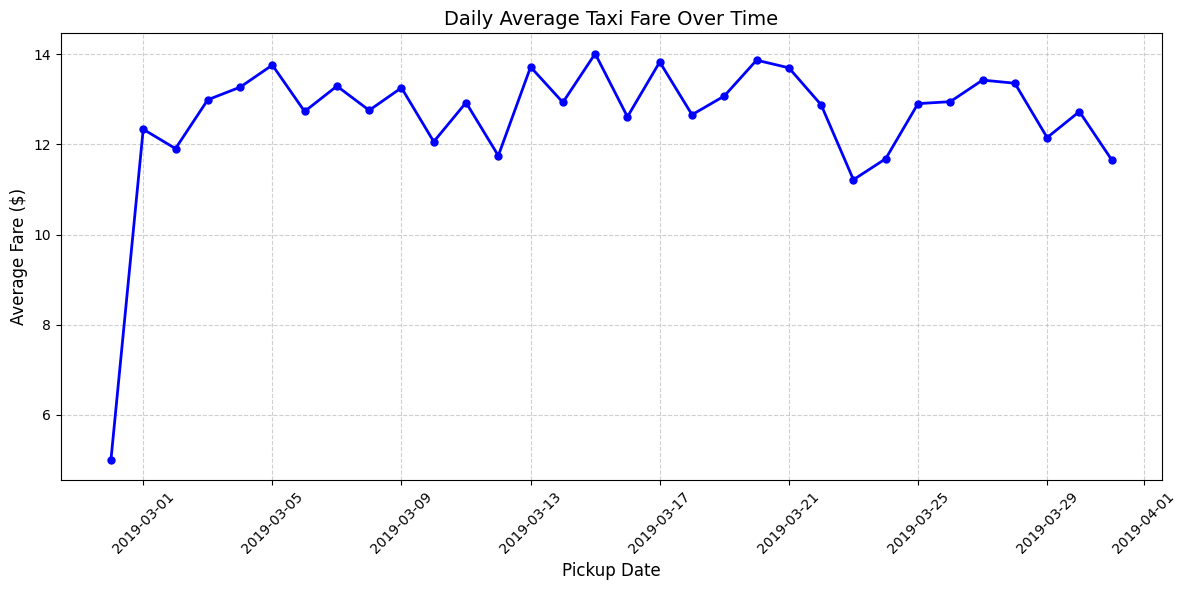

In [14]:
#For a cleaner and more meaningful line chart, I am plotting the average taxi fare per day instead of every individual trip.
import pandas as pd
import matplotlib.pyplot as plt

# Convert pickup column into datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Extract date from pickup timestamp
df['pickup_date'] = df['pickup'].dt.date

# Calculate average fare for each day
daily_fare = df.groupby('pickup_date')['fare'].mean()

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(daily_fare.index, daily_fare.values,
         color='blue',
         marker='o',
         linestyle='-',
         linewidth=2,
         markersize=5)

# Add title and labels
plt.title('Daily Average Taxi Fare Over Time', fontsize=14)
plt.xlabel('Pickup Date', fontsize=12)
plt.ylabel('Average Fare ($)', fontsize=12)

# Add grid
plt.grid(True, linestyle='--', alpha=0.6)

# Rotate x-axis labels
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

### Key Insights:

1. **Fare Fluctuations:** The average taxi fare varies across different pickup dates, indicating changes in trip costs over time.

2. **Daily Variation:** Some days show higher average fares compared to others, suggesting differences in trip distances and travel patterns.

3. **Peak Fare Periods:** Higher average fare values indicate days when passengers generally paid more for taxi services.

4. **No Consistent Trend:** The daily average fares fluctuate rather than showing a continuous upward or downward trend.

5. **Data Visualization:** Grouping individual taxi trips by date and calculating the average fare makes the line chart easier to understand and interpret.

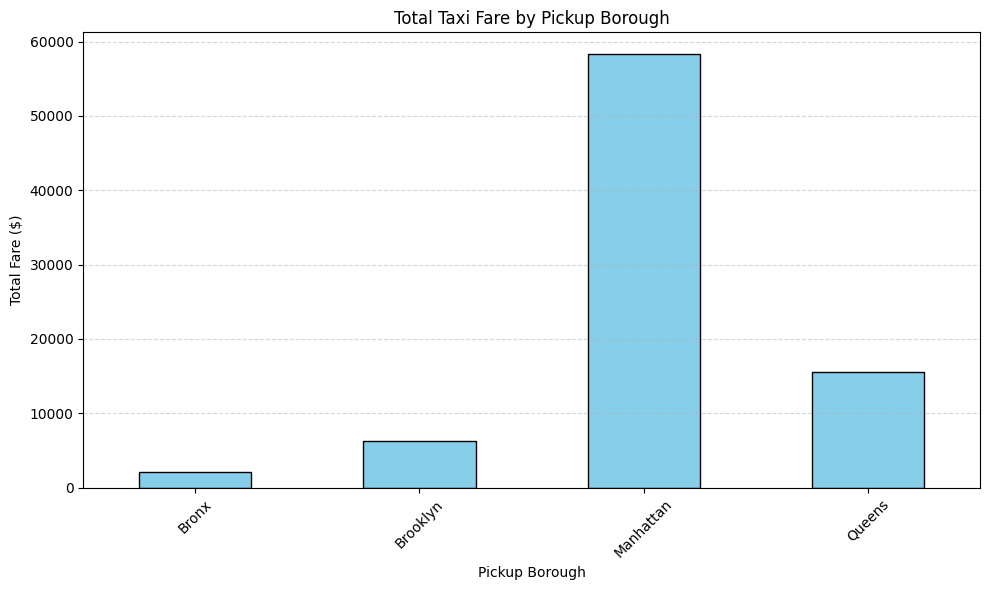

In [17]:
# Bar Chart
borough_fare = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(10, 6))
borough_fare.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Total Taxi Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

### Key Insights – Total Taxi Fare by Pickup Borough

1. **Borough-wise Fare Distribution:** The bar chart compares the total taxi fare generated from different pickup boroughs.

2. **Revenue Comparison:** Boroughs with taller bars contribute a higher total fare compared to boroughs with shorter bars.

3. **Variation in Taxi Activity:** Differences in total fare may indicate variations in taxi demand, trip frequency, and travel distances across boroughs.

4. **Business Insights:** The borough generating the highest total fare may represent an important area for taxi service operations and revenue generation.

payment
credit card    4588
cash           1795
Name: count, dtype: int64


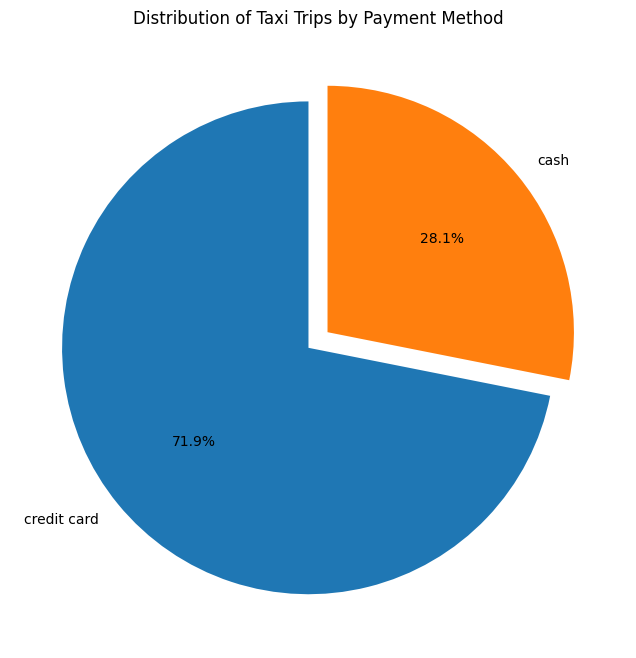

In [18]:
# Pie chart
payment_counts = df['payment'].value_counts()

print(payment_counts)

plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.05] * len(payment_counts)
)

plt.title('Distribution of Taxi Trips by Payment Method')
plt.show()

### Key Insights – Distribution of Taxi Trips by Payment Method

1. **Payment Method Preference:** The pie chart illustrates the distribution of taxi trips across different payment methods, such as credit card and cash.

2. **Most Preferred Method:** The largest slice represents the most frequently used payment method among passengers.

3. **Least Preferred Method:** The smallest slice indicates the payment method used for the lowest number of trips.

4. **Percentage Distribution:** The percentage labels help compare the proportion of trips made through each payment method.

5. **Business Insights:** Understanding passenger payment preferences can help taxi service providers improve payment facilities and customer convenience.

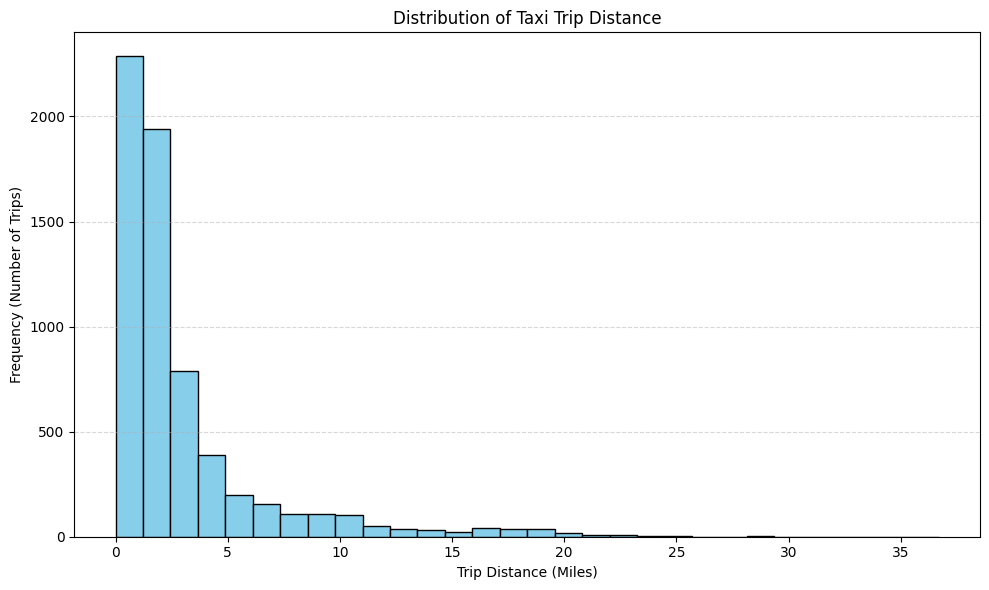

In [19]:
# Histogram
plt.figure(figsize=(10, 6))

plt.hist(df['distance'], bins=30,
         color='skyblue', edgecolor='black')

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Trip Distance (Miles)')
plt.ylabel('Frequency (Number of Trips)')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

### Key Insights – Distribution of Taxi Trip Distance

1. **Trip Distance Distribution:** The histogram illustrates how taxi trips are distributed across different distance ranges.

2. **Frequency of Short Trips:** Taller bars in the lower distance ranges indicate a higher concentration of trips within those intervals.

3. **Long-Distance Trips:** The frequency of trips at longer distances can be compared with shorter trips to understand travel patterns.

4. **Variation in Trip Distance:** The histogram helps identify the spread and variation in taxi trip distances.

5. **Outlier Identification:** Extremely long trips appearing in the right-hand tail may indicate unusual or less frequent journeys.

<Figure size 1000x600 with 0 Axes>

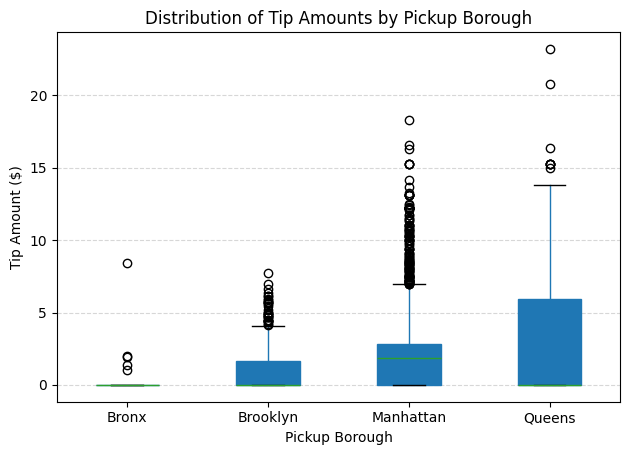

In [20]:
# Box Plot
plt.figure(figsize=(10, 6))

df.boxplot(
    column='tip',
    by='pickup_borough',
    grid=False,
    patch_artist=True
)

plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

### Key Insights – Distribution of Tip Amounts by Pickup Borough

1. **Median Tip Comparison:** The box plot helps compare the median tip amounts across different pickup boroughs and identify differences in passenger tipping behaviour.

2. **Tip Amount Variation:** The size of each box represents the interquartile range (IQR). A larger box indicates greater variation in tip amounts.

3. **Outlier Detection:** Individual points outside the whiskers represent unusually high or low tip amounts compared with the majority of trips.

4. **Consistency in Tipping:** Boroughs with smaller boxes have more consistent tip amounts, while larger boxes indicate greater variability.

5. **Borough-wise Comparison:** Comparing the distributions helps identify differences in tipping patterns across pickup locations.

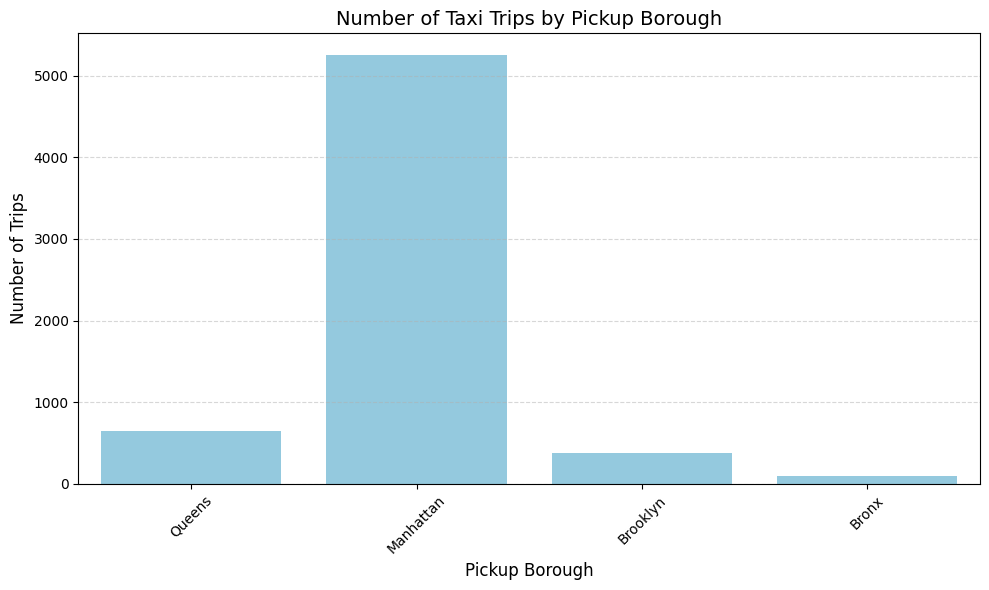

In [21]:
# Count Plot
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough', color='skyblue')

plt.title('Number of Taxi Trips by Pickup Borough', fontsize=14)
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Number of Trips', fontsize=12)

plt.xticks(rotation=45)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Key Insights – Number of Taxi Trips by Pickup Borough

1. **Borough-wise Trip Distribution:** The count plot illustrates the distribution of taxi trips across different pickup boroughs.

2. **Most Popular Pickup Location:** The borough with the tallest bar represents the location with the highest number of taxi pickups.

3. **Least Popular Pickup Location:** The borough with the shortest bar has the lowest number of recorded taxi pickups.

4. **Variation in Taxi Demand:** Differences in bar heights indicate variations in taxi demand across different geographical locations.

5. **Business Insights:** Identifying boroughs with higher pickup activity can help taxi service providers allocate vehicles and resources more effectively.

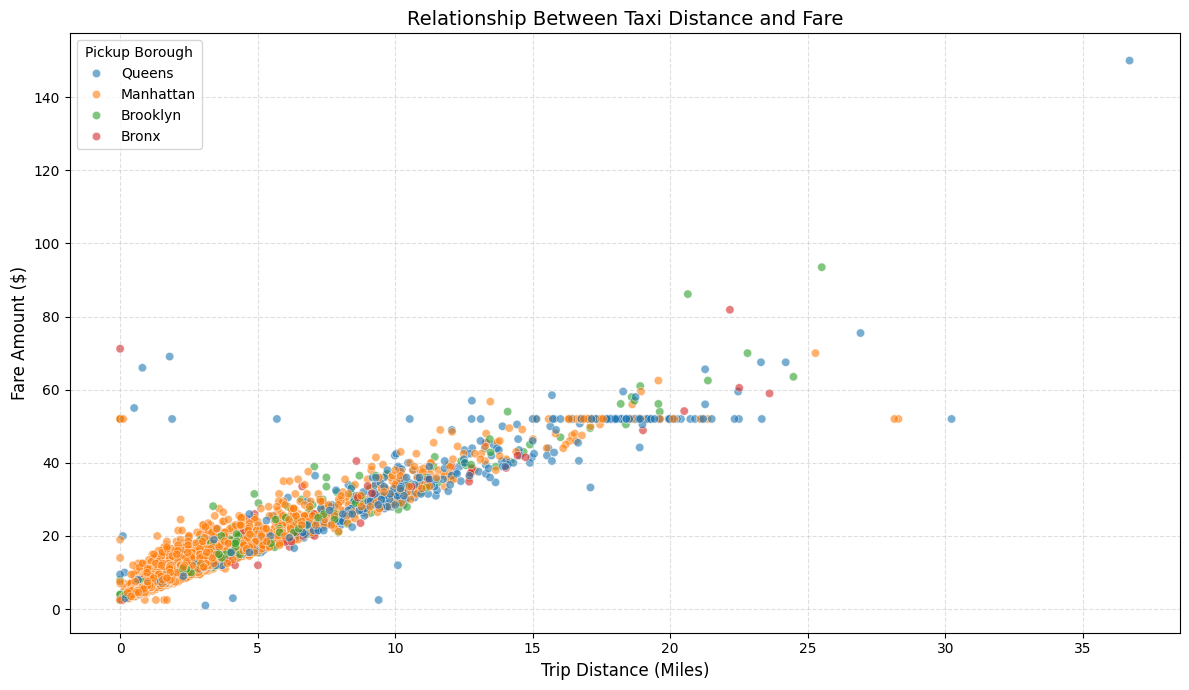

In [22]:
# Scatter plot
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough',
    alpha=0.6
)

plt.title('Relationship Between Taxi Distance and Fare', fontsize=14)
plt.xlabel('Trip Distance (Miles)', fontsize=12)
plt.ylabel('Fare Amount ($)', fontsize=12)

plt.legend(title='Pickup Borough')
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Key Insights – Relationship Between Taxi Distance and Fare

1. **Relationship Between Distance and Fare:** The scatter plot helps examine the relationship between taxi trip distance and fare amount.

2. **Positive Correlation:** A general upward pattern in the scatter plot would indicate that longer taxi trips tend to have higher fare amounts.

3. **Borough-wise Comparison:** Different colours help compare taxi trips originating from different pickup boroughs.

4. **Fare Variation:** Trips with similar distances may have different fare amounts, indicating that other factors can also influence taxi fares.

5. **Outlier Identification:** Isolated points may represent unusually high fares or long-distance trips compared with other observations.

          distance      fare       tip     tolls     total
distance  1.000000  0.947021  0.475378  0.642899  0.928371
fare      0.947021  1.000000  0.485655  0.618184  0.972376
tip       0.475378  0.485655  1.000000  0.412787  0.649050
tolls     0.642899  0.618184  0.412787  1.000000  0.691506
total     0.928371  0.972376  0.649050  0.691506  1.000000


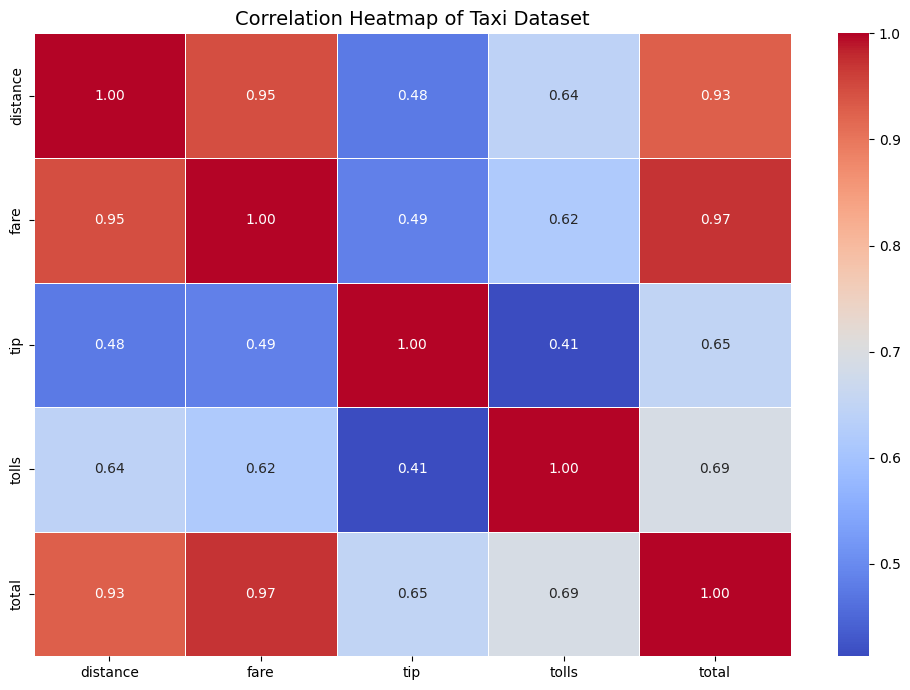

In [23]:
# Heatmap
numerical_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

correlation_matrix = numerical_data.corr()
print(correlation_matrix)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Taxi Dataset', fontsize=14)

plt.tight_layout()
plt.show()

### Key Insights – Correlation Heatmap of Taxi Dataset

1. **Distance and Fare Relationship:** The heatmap helps identify the correlation between trip distance and fare amount. A strong positive correlation would indicate that longer trips generally have higher fares.

2. **Fare and Total Amount:** Fare and total amount may show a strong positive correlation because the total trip amount includes the fare along with additional charges.

3. **Tip and Total Amount:** The correlation between tip and total helps understand how tipping amounts are associated with the overall amount paid by passengers.

4. **Tolls and Total Amount:** The relationship between toll charges and total amount helps identify the contribution of tolls to the overall trip cost.

5. **Comparison of Numerical Variables:** The heatmap makes it easier to identify which numerical variables have stronger or weaker relationships.

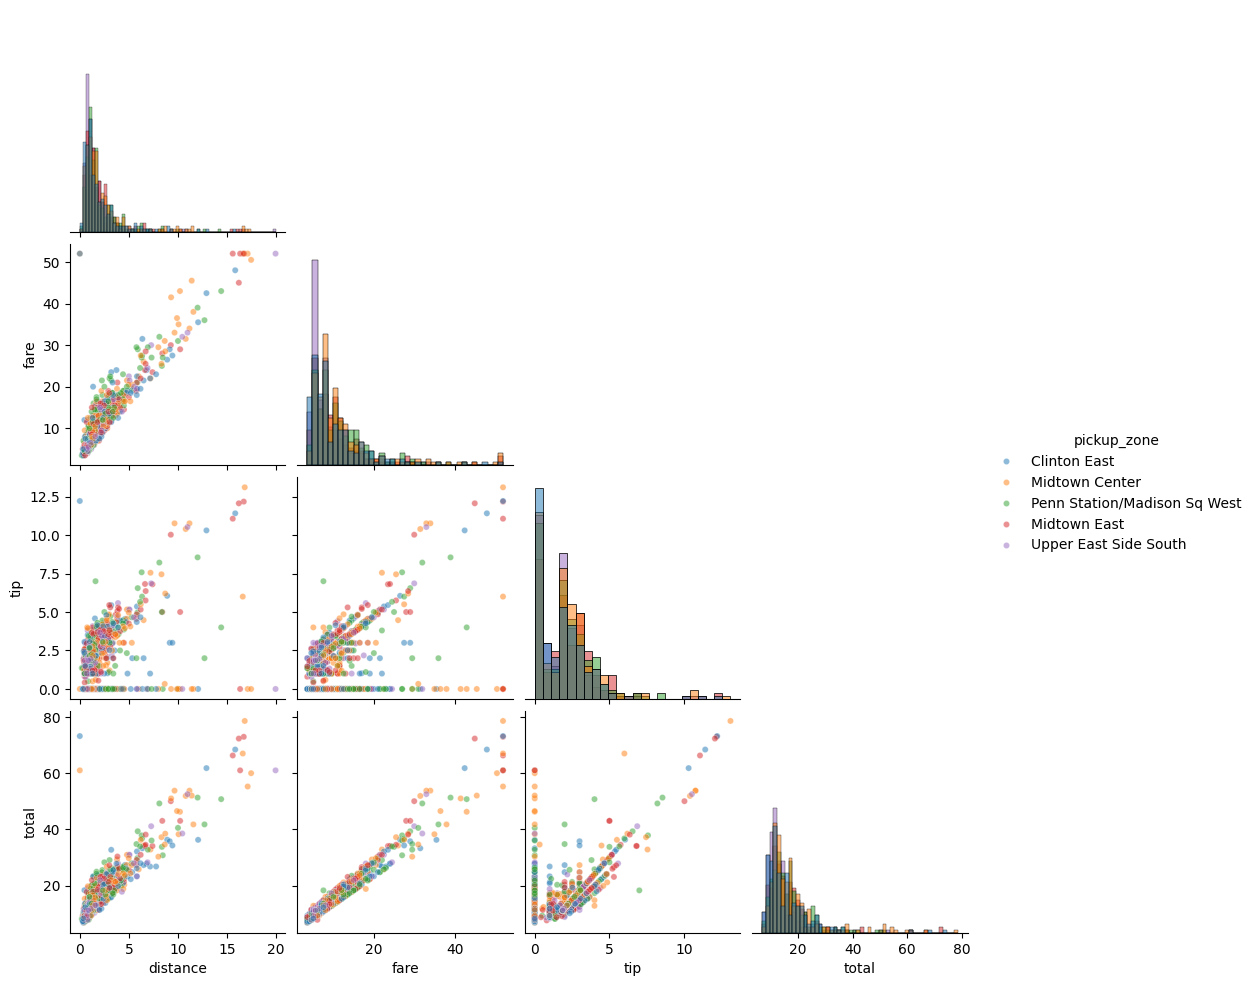

In [24]:
# Pair Plot

top_zones = df['pickup_zone'].value_counts().head(5).index

pair_data = df.loc[
    df['pickup_zone'].isin(top_zones),
    ['distance', 'fare', 'tip', 'total', 'pickup_zone']
].dropna()

sns.pairplot(
    data=pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone',
    palette='tab10',
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.5, 's': 20}
)

plt.show()

### Key Insights – Pairwise Relationships Between Taxi Variables

1. **Distance and Fare Relationship:** The pair plot helps identify the relationship between trip distance and fare amount. Longer trips may generally be associated with higher fares.

2. **Fare and Total Amount:** The visualization helps examine how fare amounts contribute to the overall trip amount.

3. **Distance and Tip Relationship:** It helps understand whether passengers taking longer trips tend to provide higher tips.

4. **Pickup Zone Comparison:** Different colours represent different pickup zones, allowing comparisons of trip patterns and fare distributions across locations.

5. **Distribution of Variables:** The diagonal histograms provide an overview of the distribution and frequency of each numerical variable.

6. **Unusual Observations:** Scattered points away from the main clusters may indicate unusually long trips or high fare and tip amounts.

/tmp/ipykernel_4150/347914745.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


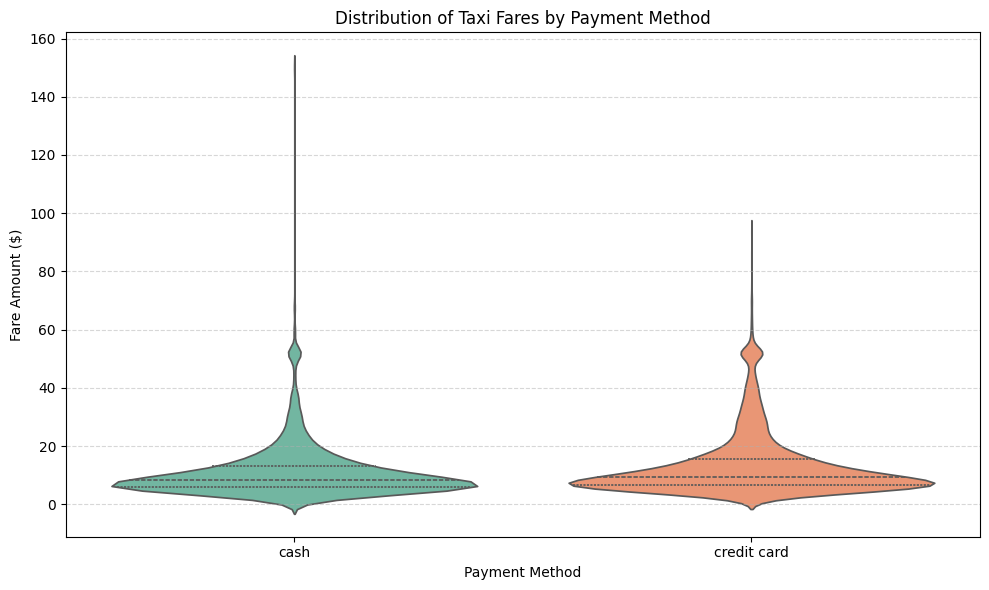

In [25]:
# Violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare',
    palette='Set2',
    inner='quartile'
)

plt.title('Distribution of Taxi Fares by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount ($)')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

### Key Insights – Distribution of Taxi Fares by Payment Method

1. **Payment-wise Fare Distribution:** The violin plot illustrates how taxi fare amounts are distributed across different payment methods.

2. **Median Fare Comparison:** The median lines help compare the typical fare amounts associated with different payment methods.

3. **Fare Concentration:** Wider sections of the violins indicate fare ranges where more taxi trips are concentrated.

4. **Variation in Fare Amounts:** Differences in violin shapes indicate variations in fare distributions across payment categories.

5. **Payment Method Comparison:** The visualization helps identify whether fare distributions differ between passengers using different payment methods.